In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt

In [2]:
#!pip install PyWavelets

In [3]:
returns = pd.read_csv(
    "data/processed/returns.csv",
    index_col=0,
    parse_dates=True
)

returns.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.018225,0.015586,0.014965,-0.137818
2015-01-06,-0.009463,0.017857,0.011334,0.041796
2015-01-07,0.012384,-0.001977,-0.005909,0.028073
2015-01-08,0.017589,-0.013332,-0.004217,-0.038046
2015-01-09,-0.008046,0.010893,0.011321,0.024607


In [4]:
print("Start date:", returns.index.min())
print("End date:", returns.index.max())
print("Observations:", len(returns))

print("\nColumns:")
print(returns.columns.tolist())

print("\nMissing values:")
print(returns.isna().sum())

Start date: 2015-01-05 00:00:00
End date: 2026-09-30 00:00:00
Observations: 2952

Columns:
['SPY', 'TLT', 'GLD', 'BTC-USD']

Missing values:
SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64


In [5]:
WAVELET = "db4"
LEVEL = 6
print("Wavelet:", WAVELET)
print("Decomposition level:", LEVEL)

Wavelet: db4
Decomposition level: 6


In [6]:
wavelet_object = pywt.Wavelet(WAVELET)

max_level = pywt.dwt_max_level(
    len(returns),
    wavelet_object.dec_len
)

print("Maximum possible level:", max_level)
print("Requested level:", LEVEL)

Maximum possible level: 8
Requested level: 6


In [7]:
def reconstruct_component(
    series,
    wavelet="db4",
    level=6,
    component_level=1
):
    """
    Reconstruct one wavelet detail component.

    component_level:
    1 -> D1
    2 -> D2
    3 -> D3
    4 -> D4
    5 -> D5
    6 -> D6
    """

    values = np.asarray(series, dtype=float)

    # Wavelet decomposition
    coeffs = pywt.wavedec(
        values,
        wavelet=wavelet,
        level=level,
        mode="symmetric"
    )

    # coeffs are arranged as:
    # [A6, D6, D5, D4, D3, D2, D1]

    selected = [
        np.zeros_like(c)
        for c in coeffs
    ]

    # Convert D1...D6 into the correct list position
    index = level - component_level + 1

    selected[index] = coeffs[index]

    # Reconstruct only the selected detail component
    reconstructed = pywt.waverec(
        selected,
        wavelet=wavelet,
        mode="symmetric"
    )

    # Sometimes waverec produces one extra point
    reconstructed = reconstructed[:len(values)]

    return reconstructed

In [8]:
spy_d1_array = reconstruct_component(
    returns["SPY"],
    wavelet=WAVELET,
    level=LEVEL,
    component_level=1
)

print("Original length:", len(returns))
print("D1 length:", len(spy_d1_array))

Original length: 2952
D1 length: 2952


In [9]:
spy_d1 = pd.Series(
    spy_d1_array,
    index=returns.index,
    name="SPY_D1"
)

spy_d1.head()

2015-01-05    0.002133
2015-01-06   -0.008827
2015-01-07    0.005826
2015-01-08    0.011027
2015-01-09   -0.012569
Name: SPY_D1, dtype: float64

In [10]:
spy_d1[:10]

2015-01-05    0.002133
2015-01-06   -0.008827
2015-01-07    0.005826
2015-01-08    0.011027
2015-01-09   -0.012569
2015-01-12   -0.002835
2015-01-13    0.006100
2015-01-14    0.001156
2015-01-15   -0.005312
2015-01-16    0.008987
Name: SPY_D1, dtype: float64

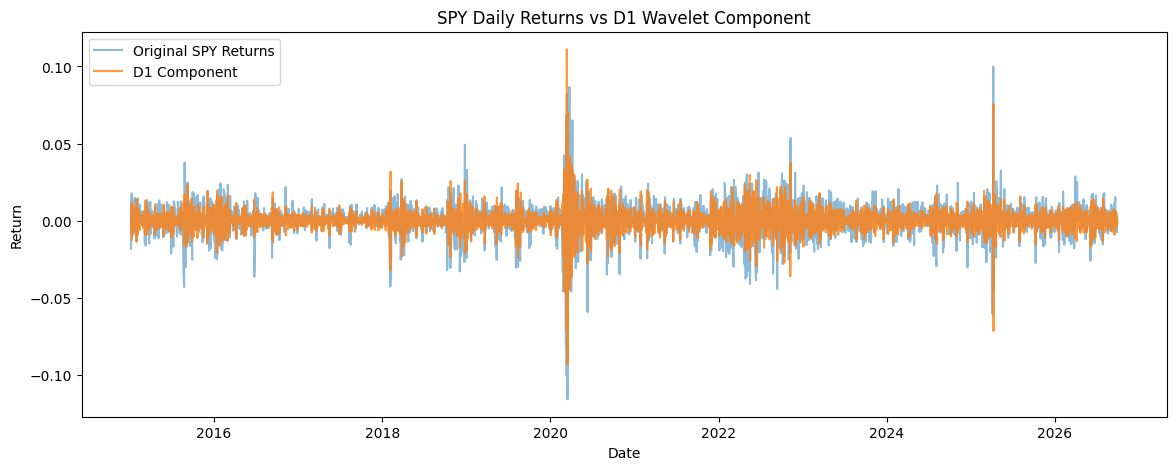

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(
    returns.index,
    returns["SPY"],
    label="Original SPY Returns",
    alpha=0.5
)

plt.plot(
    spy_d1.index,
    spy_d1,
    label="D1 Component",
    alpha=0.8
)

plt.title("SPY Daily Returns vs D1 Wavelet Component")
plt.xlabel("Date")
plt.ylabel("Return")
plt.legend()

plt.show()

In [12]:
spy_components = {}

for component_level in range(1, 7):

    reconstructed = reconstruct_component(
        returns["SPY"],
        wavelet=WAVELET,
        level=LEVEL,
        component_level=component_level
    )

    spy_components[f"D{component_level}"] = reconstructed

In [13]:
spy_wavelets = pd.DataFrame(
    spy_components,
    index=returns.index
)

spy_wavelets.head()

,D1,D2,D3,D4,D5,D6
2015-01-05,0.002133,-0.016360,-0.001645,-0.000998,-0.001129,0.000138
2015-01-06,-0.008827,-0.001749,0.003145,-0.000645,-0.001272,0.000202
2015-01-07,0.005826,0.003773,0.004461,-0.000272,-0.001401,0.000267
2015-01-08,0.011027,0.006431,0.001416,0.000113,-0.001511,0.000333
2015-01-09,-0.012569,0.006944,-0.001677,0.000658,-0.001635,0.000403


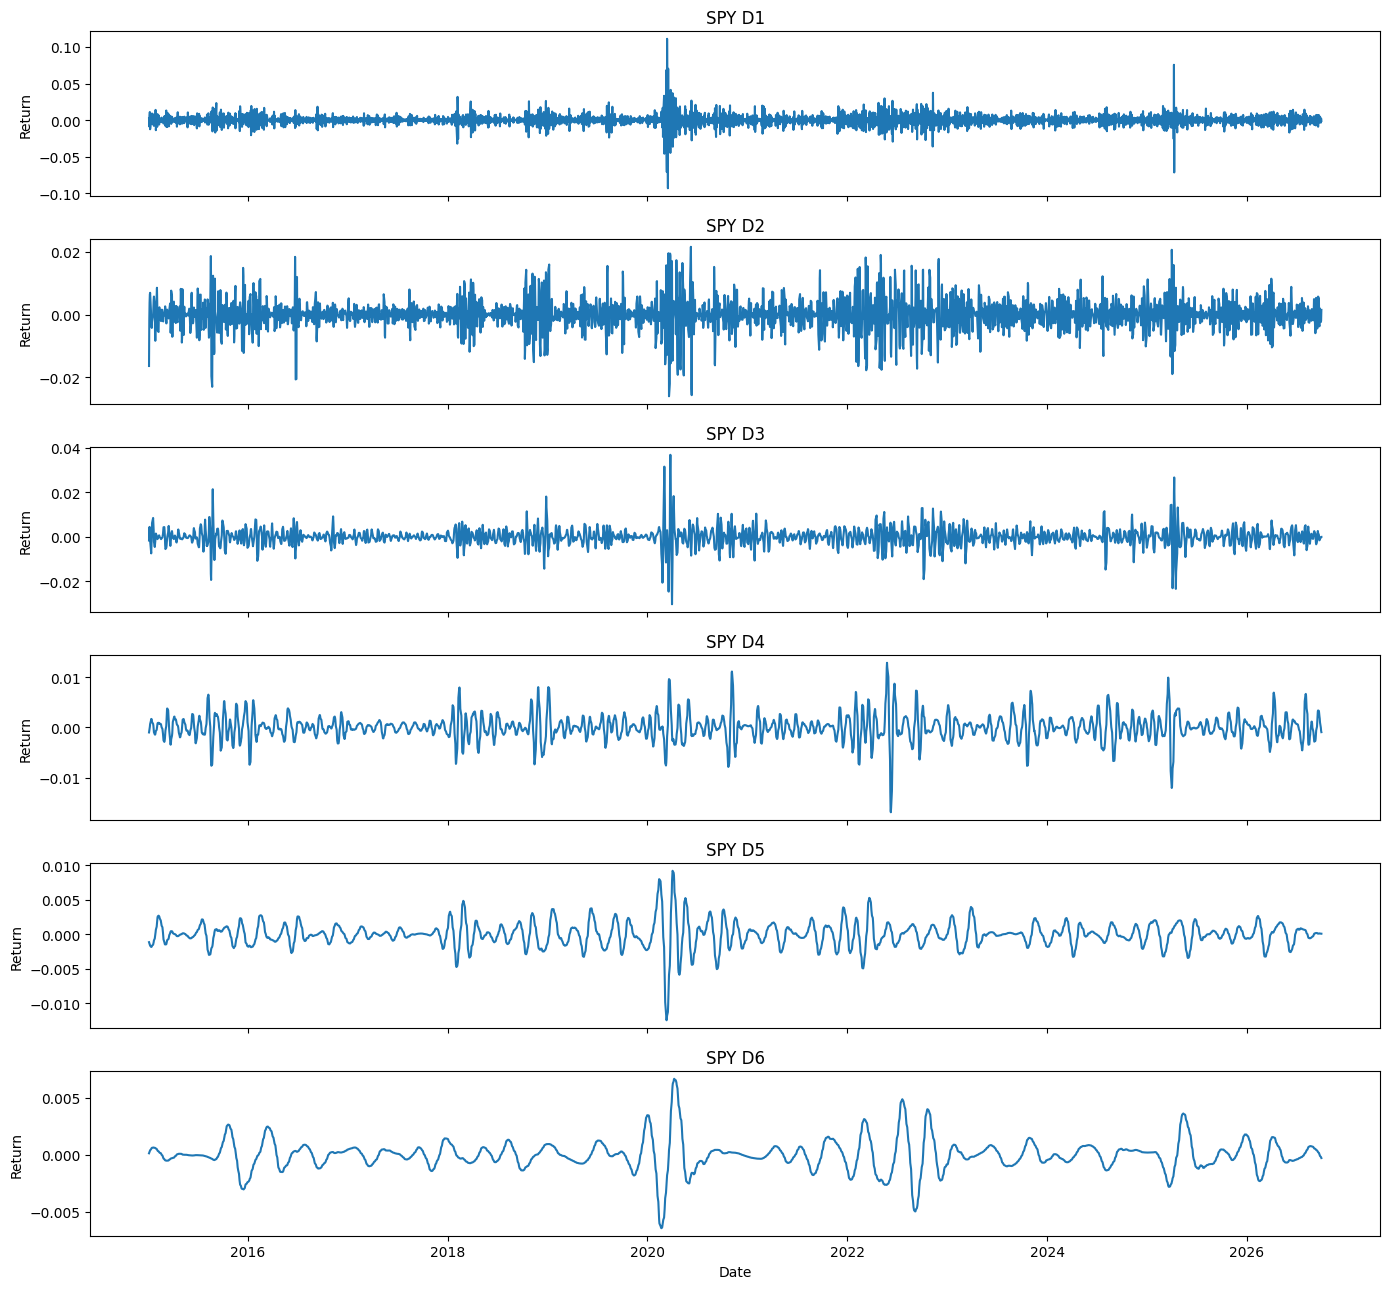

In [14]:
fig, axes = plt.subplots(
    6,
    1,
    figsize=(14, 13),
    sharex=True
)

for i in range(6):

    level_name = f"D{i+1}"

    axes[i].plot(
        spy_wavelets.index,
        spy_wavelets[level_name]
    )

    axes[i].set_title(
        f"SPY {level_name}"
    )

    axes[i].set_ylabel("Return")

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [15]:
wavelet_components = {}

for asset in returns.columns:

    asset_components = {}

    for component_level in range(1, 7):

        reconstructed = reconstruct_component(
            returns[asset],
            wavelet=WAVELET,
            level=LEVEL,
            component_level=component_level
        )

        asset_components[f"D{component_level}"] = reconstructed

    wavelet_components[asset] = pd.DataFrame(
        asset_components,
        index=returns.index
    )

In [16]:
wavelet_components["SPY"].head()

,D1,D2,D3,D4,D5,D6
2015-01-05,0.002133,-0.016360,-0.001645,-0.000998,-0.001129,0.000138
2015-01-06,-0.008827,-0.001749,0.003145,-0.000645,-0.001272,0.000202
2015-01-07,0.005826,0.003773,0.004461,-0.000272,-0.001401,0.000267
2015-01-08,0.011027,0.006431,0.001416,0.000113,-0.001511,0.000333
2015-01-09,-0.012569,0.006944,-0.001677,0.000658,-0.001635,0.000403


In [17]:
wavelet_components["BTC-USD"].head()

,D1,D2,D3,D4,D5,D6
2015-01-05,-0.010207,-0.105677,0.002149,-0.000841,-0.006121,-0.003545
2015-01-06,0.029296,0.007574,0.031819,-0.004122,-0.006464,-0.003256
2015-01-07,-0.018697,0.039556,0.036930,-0.007603,-0.006635,-0.002973
2015-01-08,-0.050863,0.032107,0.013214,-0.011256,-0.006608,-0.002700
2015-01-09,0.057210,0.019714,-0.016151,-0.015791,-0.006616,-0.002391


In [18]:
for asset in returns.columns:
    print(
        asset,
        wavelet_components[asset].shape
    )

SPY (2952, 6)
TLT (2952, 6)
GLD (2952, 6)
BTC-USD (2952, 6)


In [19]:
short_horizon = pd.DataFrame(
    index=returns.index
)

for asset in returns.columns:

    short_horizon[asset] = (
        wavelet_components[asset]["D1"]
        +
        wavelet_components[asset]["D2"]
    )

short_horizon.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.014227,0.006434,0.007803,-0.115884
2015-01-06,-0.010576,0.012747,0.006051,0.036870
2015-01-07,0.009599,-0.005272,-0.010182,0.020860
2015-01-08,0.017459,-0.017803,-0.008664,-0.018756
2015-01-09,-0.005624,0.005944,0.007053,0.076924


In [20]:
medium_horizon = pd.DataFrame(
    index=returns.index
)

for asset in returns.columns:

    medium_horizon[asset] = (
        wavelet_components[asset]["D3"]
        +
        wavelet_components[asset]["D4"]
    )

medium_horizon.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.002643,0.004026,0.001675,0.001308
2015-01-06,0.002501,0.000024,-0.000232,0.027697
2015-01-07,0.004189,-0.001727,-0.001272,0.029327
2015-01-08,0.001530,-0.000463,-0.001128,0.001958
2015-01-09,-0.001019,0.000101,-0.001340,-0.031942


In [21]:
long_horizon = pd.DataFrame(
    index=returns.index
)

for asset in returns.columns:

    long_horizon[asset] = (
        wavelet_components[asset]["D5"]
        +
        wavelet_components[asset]["D6"]
    )

long_horizon.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.000991,0.002248,0.003078,-0.009665
2015-01-06,-0.001071,0.002325,0.003249,-0.009720
2015-01-07,-0.001134,0.002384,0.003424,-0.009608
2015-01-08,-0.001178,0.002421,0.003605,-0.009308
2015-01-09,-0.001232,0.002463,0.003792,-0.009007


In [22]:
print("Original:", returns.shape)
print("Short:", short_horizon.shape)
print("Medium:", medium_horizon.shape)
print("Long:", long_horizon.shape)

Original: (2952, 4)
Short: (2952, 4)
Medium: (2952, 4)
Long: (2952, 4)


In [23]:
print("Short horizon missing values:")
print(short_horizon.isna().sum())

print("\nMedium horizon missing values:")
print(medium_horizon.isna().sum())

print("\nLong horizon missing values:")
print(long_horizon.isna().sum())

Short horizon missing values:
SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64

Medium horizon missing values:
SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64

Long horizon missing values:
SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64


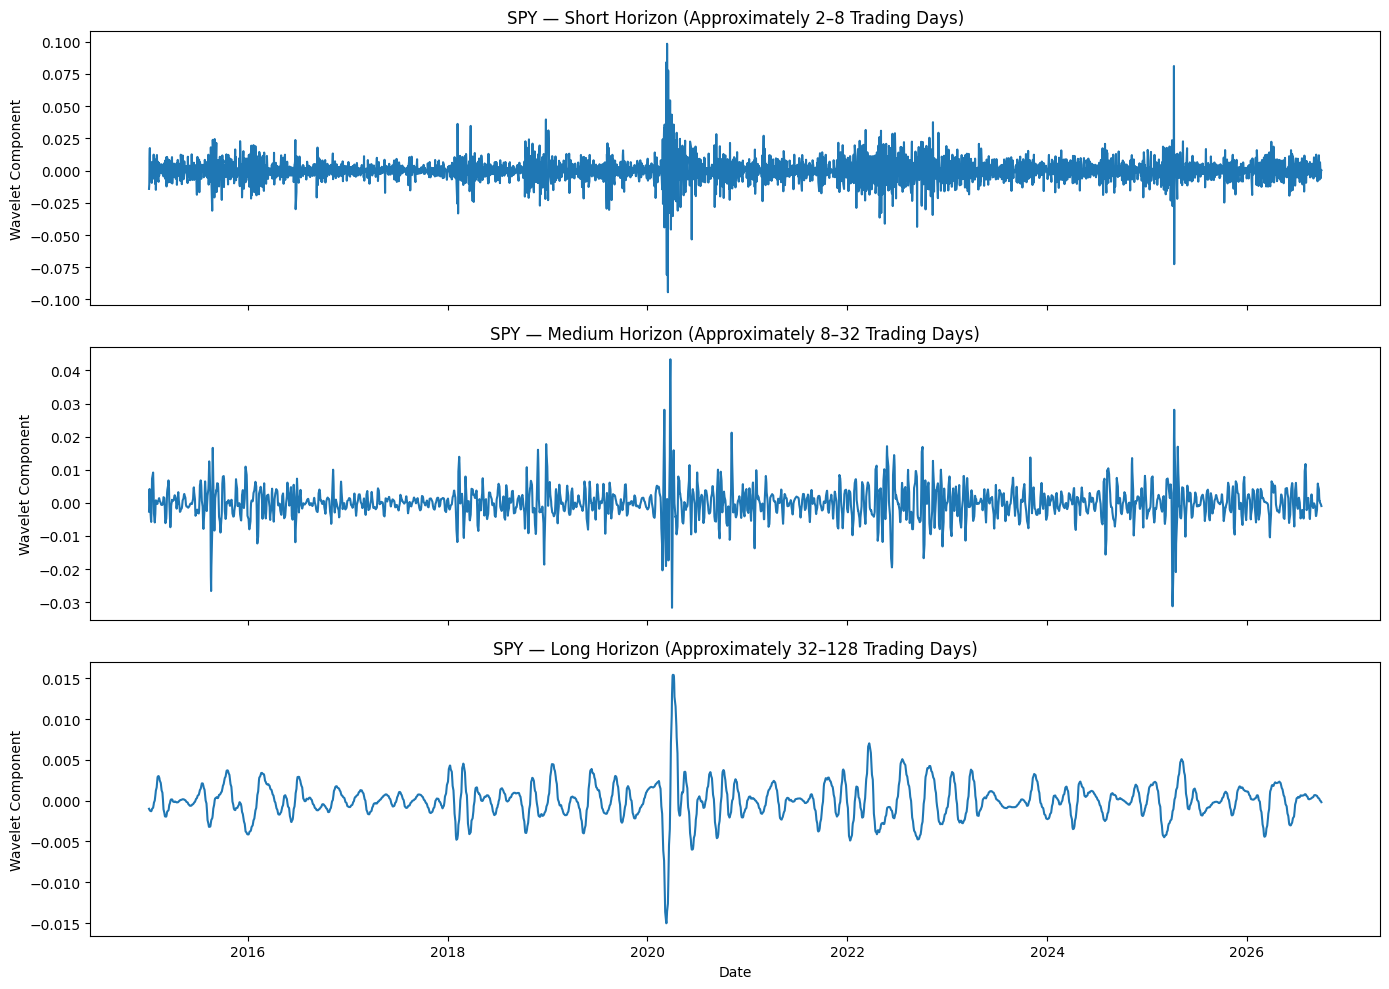

In [24]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(
    short_horizon.index,
    short_horizon["SPY"]
)

axes[0].set_title(
    "SPY — Short Horizon (Approximately 2–8 Trading Days)"
)

axes[1].plot(
    medium_horizon.index,
    medium_horizon["SPY"]
)

axes[1].set_title(
    "SPY — Medium Horizon (Approximately 8–32 Trading Days)"
)

axes[2].plot(
    long_horizon.index,
    long_horizon["SPY"]
)

axes[2].set_title(
    "SPY — Long Horizon (Approximately 32–128 Trading Days)"
)

axes[2].set_xlabel("Date")

for ax in axes:
    ax.set_ylabel("Wavelet Component")

plt.tight_layout()
plt.show()

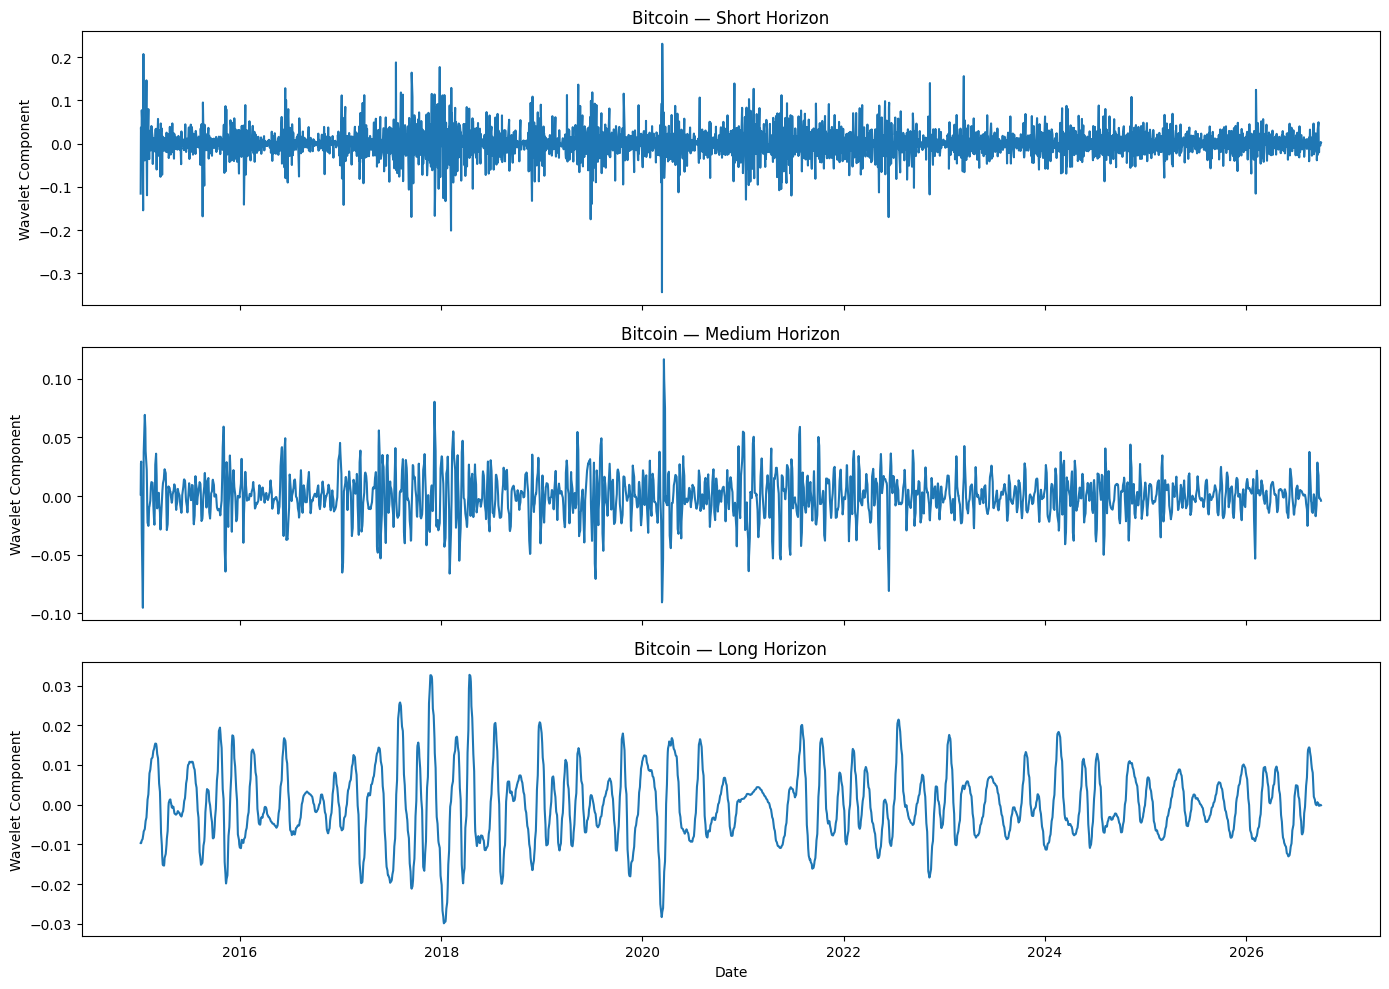

In [25]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(
    short_horizon.index,
    short_horizon["BTC-USD"]
)

axes[0].set_title(
    "Bitcoin — Short Horizon"
)

axes[1].plot(
    medium_horizon.index,
    medium_horizon["BTC-USD"]
)

axes[1].set_title(
    "Bitcoin — Medium Horizon"
)

axes[2].plot(
    long_horizon.index,
    long_horizon["BTC-USD"]
)

axes[2].set_title(
    "Bitcoin — Long Horizon"
)

axes[2].set_xlabel("Date")

for ax in axes:
    ax.set_ylabel("Wavelet Component")

plt.tight_layout()
plt.show()

In [26]:
horizon_std = pd.DataFrame({
    "Short": short_horizon.std(),
    "Medium": medium_horizon.std(),
    "Long": long_horizon.std()
})

horizon_std

,Short,Medium,Long
SPY,0.009708,0.004695,0.002223
TLT,0.008323,0.003595,0.001714
GLD,0.008925,0.004474,0.002105
BTC-USD,0.035916,0.017831,0.008939


In [27]:
short_corr = short_horizon.corr()
short_corr

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.202881,0.038344,0.246965
TLT,-0.202881,1.000000,0.245609,-0.024755
GLD,0.038344,0.245609,1.000000,0.097743
BTC-USD,0.246965,-0.024755,0.097743,1.000000


In [28]:
medium_corr = medium_horizon.corr()
medium_corr

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.044955,0.200407,0.192366
TLT,-0.044955,1.000000,0.277077,0.037819
GLD,0.200407,0.277077,1.000000,0.157349
BTC-USD,0.192366,0.037819,0.157349,1.000000


In [29]:
long_corr = long_horizon.corr()
long_corr

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,0.015384,0.181614,0.337318
TLT,0.015384,1.000000,0.361312,-0.018351
GLD,0.181614,0.361312,1.000000,0.079855
BTC-USD,0.337318,-0.018351,0.079855,1.000000


In [30]:
pairs = [
    ("SPY", "TLT"),
    ("SPY", "GLD"),
    ("SPY", "BTC-USD"),
    ("TLT", "GLD"),
    ("TLT", "BTC-USD"),
    ("GLD", "BTC-USD")
]

In [31]:
correlation_results = []

for asset1, asset2 in pairs:

    result = {
        "Pair": f"{asset1}-{asset2}",

        "Short": short_horizon[
            asset1
        ].corr(
            short_horizon[asset2]
        ),

        "Medium": medium_horizon[
            asset1
        ].corr(
            medium_horizon[asset2]
        ),

        "Long": long_horizon[
            asset1
        ].corr(
            long_horizon[asset2]
        )
    }

    correlation_results.append(result)

correlation_by_horizon = pd.DataFrame(
    correlation_results
)

correlation_by_horizon

,Pair,Short,Medium,Long
0,SPY-TLT,-0.202881,-0.044955,0.015384
1,SPY-GLD,0.038344,0.200407,0.181614
2,SPY-BTC-USD,0.246965,0.192366,0.337318
3,TLT-GLD,0.245609,0.277077,0.361312
4,TLT-BTC-USD,-0.024755,0.037819,-0.018351
5,GLD-BTC-USD,0.097743,0.157349,0.079855


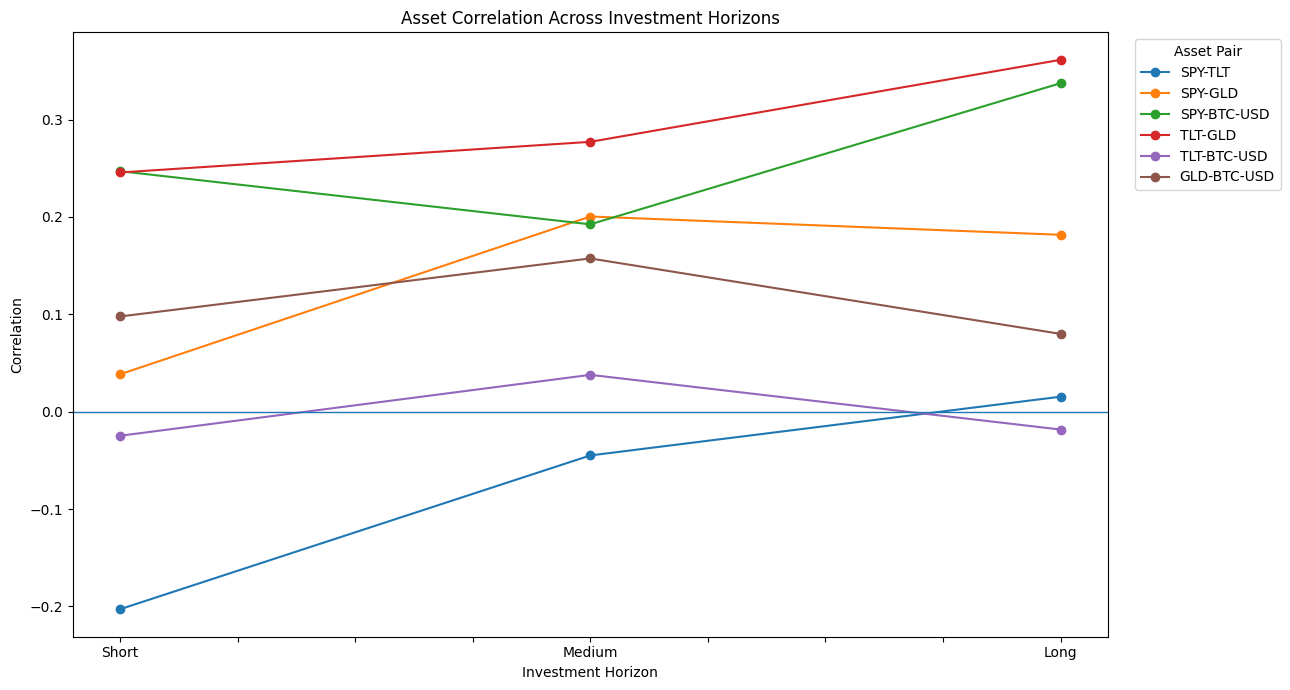

In [32]:
correlation_plot = (
    correlation_by_horizon
    .set_index("Pair")
    .T
)

correlation_plot.plot(
    figsize=(13, 7),
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Asset Correlation Across Investment Horizons"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Correlation"
)

plt.legend(
    title="Asset Pair",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [33]:
regimes = pd.read_csv(
    "data/processed/market_regimes.csv",
    index_col=0,
    parse_dates=True
)

regimes.head()

,SPY_Vol_20,Regime
2015-02-03,0.175336,Normal
2015-02-04,0.170624,Normal
2015-02-05,0.167277,Normal
2015-02-06,0.165370,Normal
2015-02-09,0.153540,Normal


In [34]:
regimes["Regime"].value_counts()

Regime
Normal    2375
Stress     557
Name: count, dtype: int64

In [35]:
regime_labels = regimes[["Regime"]].copy()

regime_labels.head()

,Regime
2015-02-03,Normal
2015-02-04,Normal
2015-02-05,Normal
2015-02-06,Normal
2015-02-09,Normal


In [36]:
short_with_regime = short_horizon.join(
    regime_labels,
    how="inner"
)

short_with_regime.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.012082,-0.017108,-0.007482,-0.021634,Normal
2015-02-04,-0.006297,0.011303,0.009490,0.012572,Normal
2015-02-05,0.007191,0.000838,0.007487,-0.036156,Normal
2015-02-06,-0.006461,-0.007030,-0.020922,0.029333,Normal
2015-02-09,-0.008716,0.007205,0.009437,-0.009858,Normal


In [37]:
medium_with_regime = medium_horizon.join(
    regime_labels,
    how="inner"
)

medium_with_regime.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,-0.000069,-0.001472,-0.001685,-0.023885,Normal
2015-02-04,-0.000331,-0.005916,-0.002090,-0.014542,Normal
2015-02-05,-0.000280,-0.007571,-0.002004,-0.009379,Normal
2015-02-06,0.000402,-0.006167,-0.001047,-0.008761,Normal
2015-02-09,0.000862,-0.003914,-0.000371,-0.003918,Normal


In [38]:
long_with_regime = long_horizon.join(
    regime_labels,
    how="inner"
)

long_with_regime.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.002050,-0.003799,-0.002451,0.004035,Normal
2015-02-04,0.002505,-0.004610,-0.003355,0.005575,Normal
2015-02-05,0.002813,-0.005179,-0.004040,0.006876,Normal
2015-02-06,0.002954,-0.005475,-0.004470,0.007909,Normal
2015-02-09,0.003018,-0.005644,-0.004795,0.008830,Normal


In [39]:
short_normal = (
    short_with_regime[
        short_with_regime["Regime"] == "Normal"
    ]
    .drop(columns="Regime")
)

short_stress = (
    short_with_regime[
        short_with_regime["Regime"] == "Stress"
    ]
    .drop(columns="Regime")
)

In [40]:
medium_normal = (
    medium_with_regime[
        medium_with_regime["Regime"] == "Normal"
    ]
    .drop(columns="Regime")
)

medium_stress = (
    medium_with_regime[
        medium_with_regime["Regime"] == "Stress"
    ]
    .drop(columns="Regime")
)

In [41]:
long_normal = (
    long_with_regime[
        long_with_regime["Regime"] == "Normal"
    ]
    .drop(columns="Regime")
)

long_stress = (
    long_with_regime[
        long_with_regime["Regime"] == "Stress"
    ]
    .drop(columns="Regime")
)

In [42]:
print("SHORT HORIZON")
print("Normal:", len(short_normal))
print("Stress:", len(short_stress))

print("\nMEDIUM HORIZON")
print("Normal:", len(medium_normal))
print("Stress:", len(medium_stress))

print("\nLONG HORIZON")
print("Normal:", len(long_normal))
print("Stress:", len(long_stress))

SHORT HORIZON
Normal: 2375
Stress: 557

MEDIUM HORIZON
Normal: 2375
Stress: 557

LONG HORIZON
Normal: 2375
Stress: 557


In [43]:
spy_btc_regime_corr = pd.DataFrame(
    {
        "Normal": [
            short_normal["SPY"].corr(
                short_normal["BTC-USD"]
            ),

            medium_normal["SPY"].corr(
                medium_normal["BTC-USD"]
            ),

            long_normal["SPY"].corr(
                long_normal["BTC-USD"]
            )
        ],

        "Stress": [
            short_stress["SPY"].corr(
                short_stress["BTC-USD"]
            ),

            medium_stress["SPY"].corr(
                medium_stress["BTC-USD"]
            ),

            long_stress["SPY"].corr(
                long_stress["BTC-USD"]
            )
        ]
    },

    index=[
        "Short",
        "Medium",
        "Long"
    ]
)

spy_btc_regime_corr

,Normal,Stress
Short,0.163642,0.427895
Medium,0.142722,0.282916
Long,0.258233,0.514786


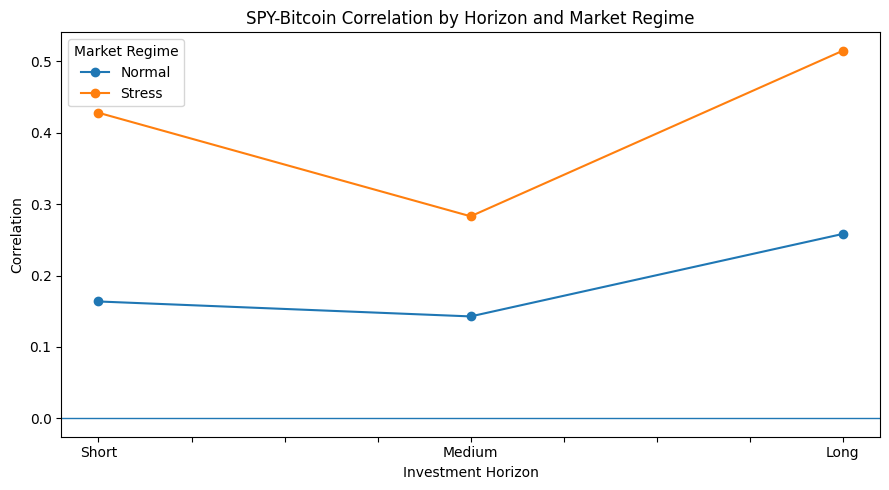

In [44]:
spy_btc_regime_corr.plot(
    figsize=(9, 5),
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "SPY-Bitcoin Correlation by Horizon and Market Regime"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Correlation"
)

plt.legend(
    title="Market Regime"
)

plt.tight_layout()
plt.show()

In [45]:
regime_correlation_results = []

horizon_datasets = {
    "Short": {
        "Normal": short_normal,
        "Stress": short_stress
    },

    "Medium": {
        "Normal": medium_normal,
        "Stress": medium_stress
    },

    "Long": {
        "Normal": long_normal,
        "Stress": long_stress
    }
}

In [46]:
for asset1, asset2 in pairs:

    row = {
        "Pair": f"{asset1}-{asset2}"
    }

    for horizon_name, regime_data in horizon_datasets.items():

        for regime_name, dataset in regime_data.items():

            column_name = (
                f"{horizon_name}_{regime_name}"
            )

            row[column_name] = (
                dataset[asset1]
                .corr(dataset[asset2])
            )

    regime_correlation_results.append(row)

In [47]:
correlation_horizon_regime = pd.DataFrame(
    regime_correlation_results
)

correlation_horizon_regime

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,-0.093329,-0.326011,-0.094466,0.034170,0.042075,-0.014236
1,SPY-GLD,0.078913,-0.005959,0.081381,0.399525,0.116292,0.358922
2,SPY-BTC-USD,0.163642,0.427895,0.142722,0.282916,0.258233,0.514786
3,TLT-GLD,0.243344,0.252966,0.279353,0.289592,0.350224,0.378717
4,TLT-BTC-USD,-0.002367,-0.078470,-0.024660,0.233854,0.040988,-0.187209
5,GLD-BTC-USD,0.088207,0.126834,0.124821,0.259775,0.068496,0.159739


In [48]:
short_horizon.to_csv(
    "data/processed/returns_short_horizon.csv"
)

medium_horizon.to_csv(
    "data/processed/returns_medium_horizon.csv"
)

long_horizon.to_csv(
    "data/processed/returns_long_horizon.csv"
)

In [49]:
short_with_regime.to_csv(
    "data/processed/short_with_regime.csv"
)

medium_with_regime.to_csv(
    "data/processed/medium_with_regime.csv"
)

long_with_regime.to_csv(
    "data/processed/long_with_regime.csv"
)

In [50]:
correlation_by_horizon.to_csv(
    "outputs/tables/correlation_by_horizon.csv",
    index=False
)

In [51]:
correlation_horizon_regime.to_csv(
    "outputs/tables/correlation_horizon_regime.csv",
    index=False
)

In [52]:
print("Notebook 04 completed successfully.")

print("\nShort horizon:")
print(short_horizon.shape)

print("\nMedium horizon:")
print(medium_horizon.shape)

print("\nLong horizon:")
print(long_horizon.shape)

print("\nShort + regime:")
print(short_with_regime.shape)

print("\nMedium + regime:")
print(medium_with_regime.shape)

print("\nLong + regime:")
print(long_with_regime.shape)

Notebook 04 completed successfully.

Short horizon:
(2952, 4)

Medium horizon:
(2952, 4)

Long horizon:
(2952, 4)

Short + regime:
(2932, 5)

Medium + regime:
(2932, 5)

Long + regime:
(2932, 5)
